### Importing all the files from S1 to S13 into a single DF:

In [7]:
# Imports:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
# Folder with the CSV files (raw string so the backslashes are read correctly)
data_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\MQ3_logs_S1-S13")

frames = []
skipped = []

for f in sorted(data_dir.glob("*.csv")):   # only files in this folder, not subfolders
    # Split into at most 5 parts, so yt_ext stays intact even if it contains "_"
    parts = f.stem.split("_", 4)
    if len(parts) != 5:
        skipped.append(f.name)
        continue

    set_id, vd_id, init_soc, user_state, yt_ext = parts

    df = pd.read_csv(f)              # e.g. for filename "S12_V2_95_SQ_G-XZhKqQAHU" 
    df["set_id"] = set_id            # e.g. "S12"
    df["vd_id"] = vd_id              # e.g. "V2"
    df["init_soc"] = int(init_soc)   # e.g. 95 (as a number)
    df["user_state"] = user_state    # e.g. "SQ"
    df["yt_ext"] = yt_ext            # e.g. "G-XZhKqQAHU"
    frames.append(df)

df_all = pd.concat(frames, ignore_index=True)

print(f"Loaded {len(frames)} files, {len(df_all)} rows, {df_all.shape[1]} columns")
if skipped:
    print("Skipped (unexpected file name):", skipped)

df_all.head()

Loaded 70 files, 21707 rows, 46 columns


,id_line,Timestamp,Elapsed (s),Level (%),Voltage (mV),Temp (C),Charge Counter (uAh),Calculated Current (mA),Calculated Power (mW),Accumulated Power (mWh),...,Video Clock,Video Session,Video Position (s),Video Position (mm:ss),Position Source,set_id,vd_id,init_soc,user_state,yt_ext
0,30,2026-10-13 18:31:42,29.61,99,4215,32.0,4953606,1701.79,7173.04,74.763,...,Running,1,0.3,00:00,manual clock,S10,V1,100,ST,KGerjHMa90s
1,31,2026-10-13 18:31:43,30.62,99,4215,32.0,4953606,1701.79,7173.04,77.731,...,Running,1,1.3,00:01,manual clock,S10,V1,100,ST,KGerjHMa90s
2,32,2026-10-13 18:31:45,32.11,99,4215,32.0,4953606,1701.79,7173.04,79.405,...,Running,1,2.8,00:02,manual clock,S10,V1,100,ST,KGerjHMa90s
3,33,2026-10-13 18:31:46,32.95,99,4215,32.0,4953606,1701.79,7173.04,81.617,...,Running,1,3.6,00:03,manual clock,S10,V1,100,ST,KGerjHMa90s
4,34,2026-10-13 18:31:47,34.06,99,4215,32.0,4953606,1701.79,7173.04,83.091,...,Running,1,4.7,00:04,manual clock,S10,V1,100,ST,KGerjHMa90s


In [9]:
combos = (
    df_all.loc[df_all["set_id"] == "S13"] # 1, 2, 3, 4, 7, 10, 11, 13
    .groupby(["set_id", "vd_id", "Video Session"], dropna=False)
    .agg(
        elapsed_min=("Elapsed (s)", "min"),
        elapsed_max=("Elapsed (s)", "max"),
        video_pos_min=("Video Position (s)", "min"),
        video_pos_max=("Video Position (s)", "max"),
    )
    .reset_index()
)

combos["Elapsed"] = combos["elapsed_max"] - combos["elapsed_min"]
combos["Video Length"] = combos["video_pos_max"] - combos["video_pos_min"]
combos["Difference"] = combos["Elapsed"] - combos["Video Length"]

print(f"{len(combos)} unique combinations")
combos

6 unique combinations


,set_id,vd_id,Video Session,elapsed_min,elapsed_max,video_pos_min,video_pos_max,Elapsed,Video Length,Difference
0,S13,V1,1,23.36,397.68,0.3,374.6,374.32,374.3,0.02
1,S13,V2,1,23.30,318.44,0.3,295.5,295.14,295.2,-0.06
2,S13,V3,1,37.31,436.79,0.7,400.2,399.48,399.5,-0.02
3,S13,V4,1,38.26,255.47,0.8,218.0,217.21,217.2,0.01
4,S13,V5,1,31.22,403.55,0.8,373.1,372.33,372.3,0.03
5,S13,V6,1,32.25,305.81,0.2,273.7,273.56,273.5,0.06


## 1. Consumption for a single video:

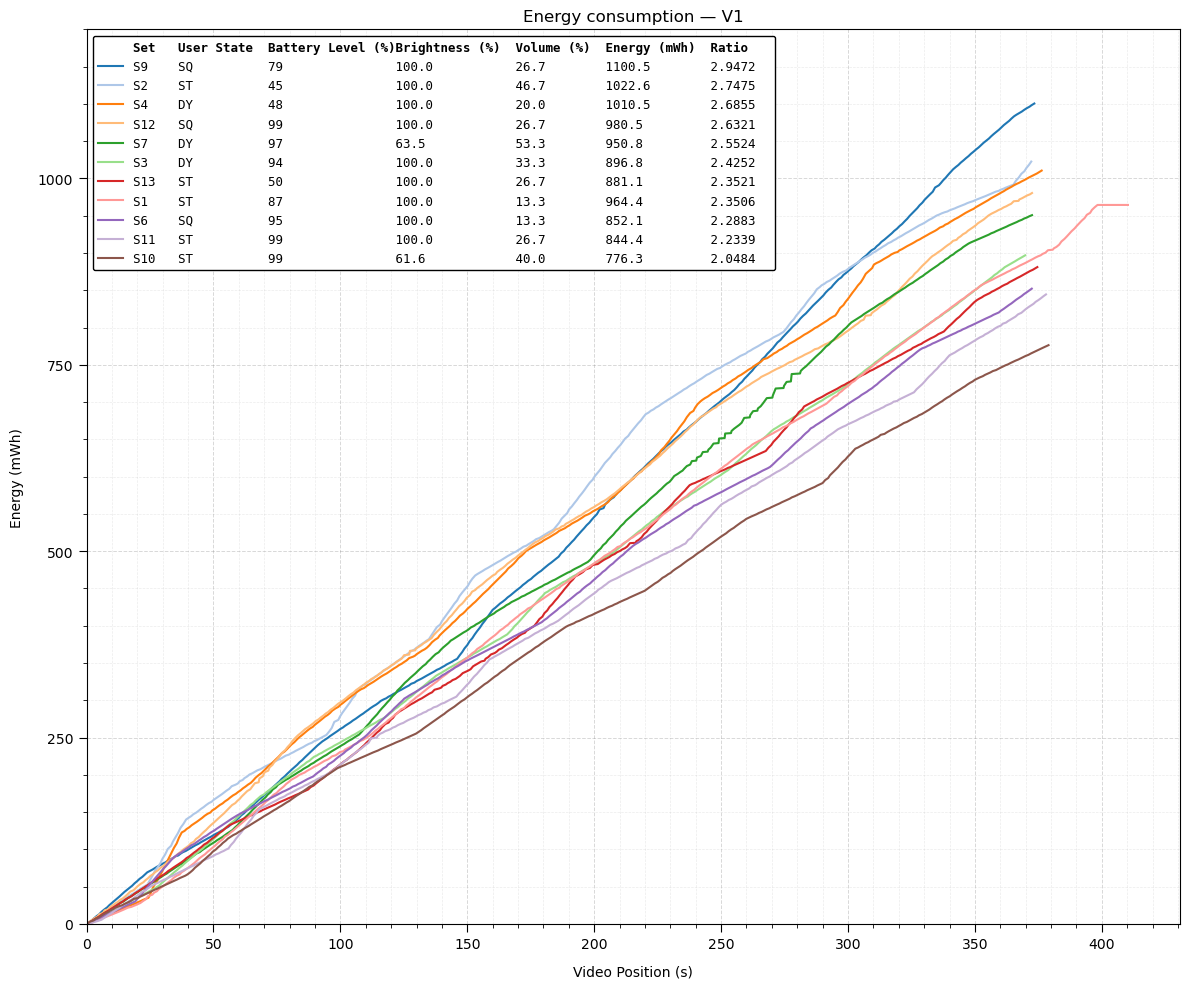

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Shift each set's accumulated power so its first value is 0
v1["Accumulated Power from start (mWh)"] = (
    v1["Accumulated Power (mWh)"]
    - v1.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
)

# Per-set info for the legend
info = v1.groupby("set_id").agg(
    level_max=("Level (%)", "max"),
    user_state=("user_state", "first"),
    bright_avg=("Brightness (%)", "mean"),
    volume_avg=("Volume (%)", "mean"),
    energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
    length_max=("Video Position (s)", "max"),
)

# Ratio: energy per second of video (zero length -> NaN)
info["ratio"] = info["energy"] / info["length_max"].replace(0, np.nan)

# Set order by ratio, highest first
sets = info.sort_values("ratio", ascending=False).index.tolist()

# Legend column widths (characters); header and values share them, all left-aligned
COL_W = {"set": 6, "state": 12, "soc": 17, "bright": 16, "volume": 12, "energy": 14, "ratio": 8}


def legend_row(set_txt, state, soc, bright, volume, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{state:<{COL_W['state']}}"
            f"{soc:<{COL_W['soc']}}{bright:<{COL_W['bright']}}"
            f"{volume:<{COL_W['volume']}}{energy:<{COL_W['energy']}}"
            f"{ratio:<{COL_W['ratio']}}")


fig, ax = plt.subplots(figsize=(12, 10))
colors = plt.cm.tab20.colors   # enough distinct colors for up to 20 sets

for i, s in enumerate(sets):
    d = v1[v1["set_id"] == s]
    r = info.loc[s]
    label = legend_row(s, r.user_state,
                       f"{r.level_max:.0f}",
                       f"{r.bright_avg:.1f}",
                       f"{r.volume_avg:.1f}",
                       f"{r.energy:.1f}",
                       f"{r.ratio:.4f}")
    ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
            label=label, color=colors[i % len(colors)], linewidth=1.5)

# Axis titles a bit further from their axes
ax.set_xlabel("Video Position (s)", labelpad=10)
ax.set_ylabel("Energy (mWh)", labelpad=10)
ax.set_title("Energy consumption — V1")

# X-axis: numbers every 50, unnumbered ticks every 10
ax.set_xlim(left=0)
ax.xaxis.set_major_locator(MultipleLocator(50))
ax.xaxis.set_minor_locator(MultipleLocator(10))

# Y-axis: numbers 0, 250, 500, 750, 1000, unnumbered ticks every 50
ax.set_ylim(0, 1200)
ax.yaxis.set_major_locator(MultipleLocator(250))
ax.yaxis.set_minor_locator(MultipleLocator(50))

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend inside the plot (upper left), in a box, with the header as the first row
header = legend_row("Set", "User State", "Battery Level (%)", "Brightness (%)",
                    "Volume (%)", "Energy (mWh)", "Ratio")
handles, labels = ax.get_legend_handles_labels()
header_handle = Line2D([], [], color="none")   # invisible line sample, keeps alignment

leg = ax.legend([header_handle] + handles, [header] + labels,
                loc="upper left", frameon=True,
                facecolor="white", edgecolor="black", framealpha=1,
                prop={"family": "monospace", "size": 9})
leg.get_texts()[0].set_fontweight("bold")       # header row in bold

fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

fig.savefig(out_dir / f"Full_Energy_consumption_V1.pdf", dpi=300, bbox_inches="tight")


plt.show()

## 1. Consumption for a single video (RENAMED):

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Shift each set's accumulated power so its first value is 0
v1["Accumulated Power from start (mWh)"] = (
    v1["Accumulated Power (mWh)"]
    - v1.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
)

# Per-set info for the legend
info = v1.groupby("set_id").agg(
    level_max=("Level (%)", "max"),
    user_state=("user_state", "first"),
    bright_avg=("Brightness (%)", "mean"),
    volume_avg=("Volume (%)", "mean"),
    energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
    length_max=("Video Position (s)", "max"),
)

# Ratio: energy per second of video (zero length -> NaN)
info["ratio"] = info["energy"] / info["length_max"].replace(0, np.nan)

# Set order by ratio, highest first
sets = info.sort_values("ratio", ascending=False).index.tolist()

# Legend column widths (characters); header and values share them, all left-aligned
COL_W = {"set": 6, "state": 12, "soc": 19, "bright": 16, "volume": 12, "energy": 14, "ratio": 8}

# Display names for the legend (data ID -> new name)
SET_RENAME = {
    "S1": "S1",  "S2": "S2",  "S3": "D1",  "S4": "D2",
    "S5": "S4",  "S6": "S5",  "S7": "D3",  "S8": "D4",
    "S9": "D5",  "S10": "S6", "S11": "S7", "S12": "D6",
    "S13": "S3",
}


def legend_row(set_txt, state, soc, bright, volume, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{state:<{COL_W['state']}}"
            f"{soc:<{COL_W['soc']}}{bright:<{COL_W['bright']}}"
            f"{volume:<{COL_W['volume']}}{energy:<{COL_W['energy']}}"
            f"{ratio:<{COL_W['ratio']}}")


fig, ax = plt.subplots(figsize=(12, 10))
colors = plt.cm.tab20.colors   # enough distinct colors for up to 20 sets

for i, s in enumerate(sets):
    d = v1[v1["set_id"] == s]
    r = info.loc[s]
    label = legend_row(SET_RENAME.get(s, s), r.user_state,
                       f"{r.level_max:.0f}",
                       f"{r.bright_avg:.1f}",
                       f"{r.volume_avg:.1f}",
                       f"{r.energy:.1f}",
                       f"{r.ratio:.4f}")
    ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
            label=label, color=colors[i % len(colors)], linewidth=1.5)

# Axis titles a bit further from their axes
ax.set_xlabel("Video Position (s)", labelpad=10)
ax.set_ylabel("Energy (mWh)", labelpad=10)
ax.set_title("Energy consumption — V1")

# X-axis: numbers every 50, unnumbered ticks every 10
ax.set_xlim(left=0)
ax.xaxis.set_major_locator(MultipleLocator(50))
ax.xaxis.set_minor_locator(MultipleLocator(10))

# Y-axis: numbers every 250, unnumbered ticks every 50
ax.set_ylim(0, 1200)
ax.yaxis.set_major_locator(MultipleLocator(250))
ax.yaxis.set_minor_locator(MultipleLocator(50))

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend inside the plot (upper left), in a box, with the header as the first row
header = legend_row("Set", "User State", "Battery Level (%)", "Brightness (%)",
                    "Volume (%)", "Energy (mWh)", "Ratio")
handles, labels = ax.get_legend_handles_labels()
header_handle = Line2D([], [], color="none")   # invisible line sample, keeps alignment

leg = ax.legend([header_handle] + handles, [header] + labels,
                loc="upper left", frameon=True,
                facecolor="white", edgecolor="black", framealpha=1,
                prop={"family": "monospace", "size": 9})
leg.get_texts()[0].set_fontweight("bold")       # header row in bold

fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

fig.savefig(out_dir / "Full_Energy_consumption_V1.pdf", dpi=300, bbox_inches="tight")

plt.show()

SyntaxError: unexpected character after line continuation character (1828415966.py, line 6)

# Consumption for ALL videos (exclusing some Sets):

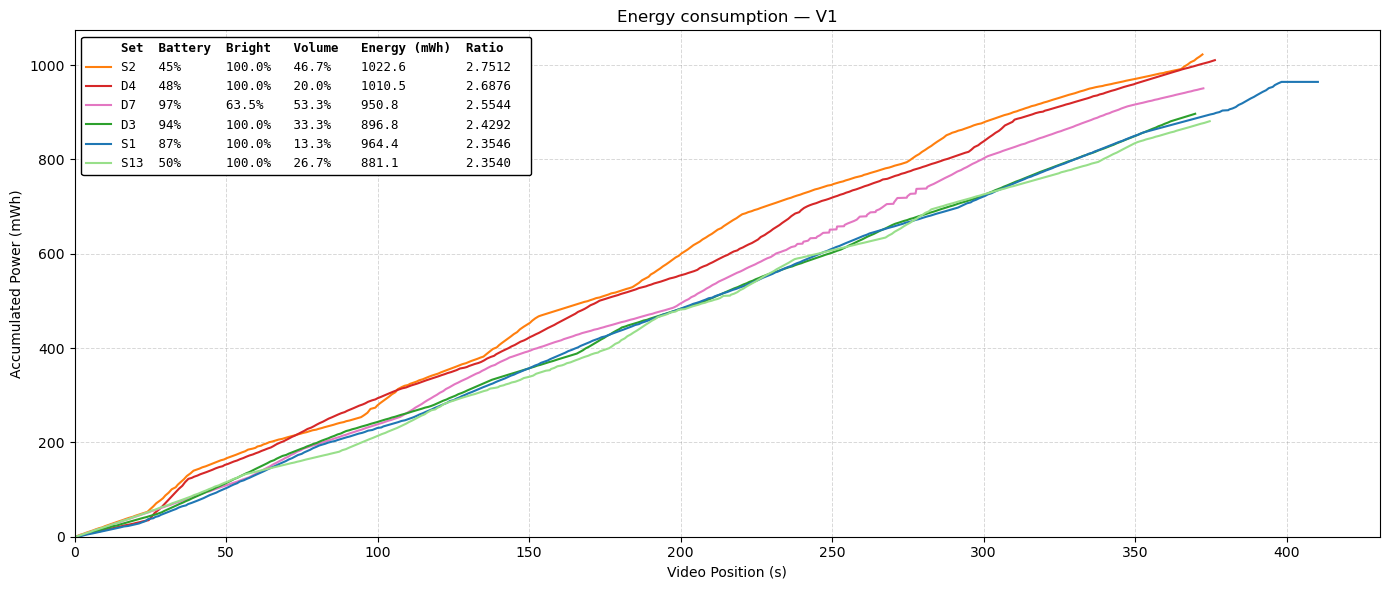

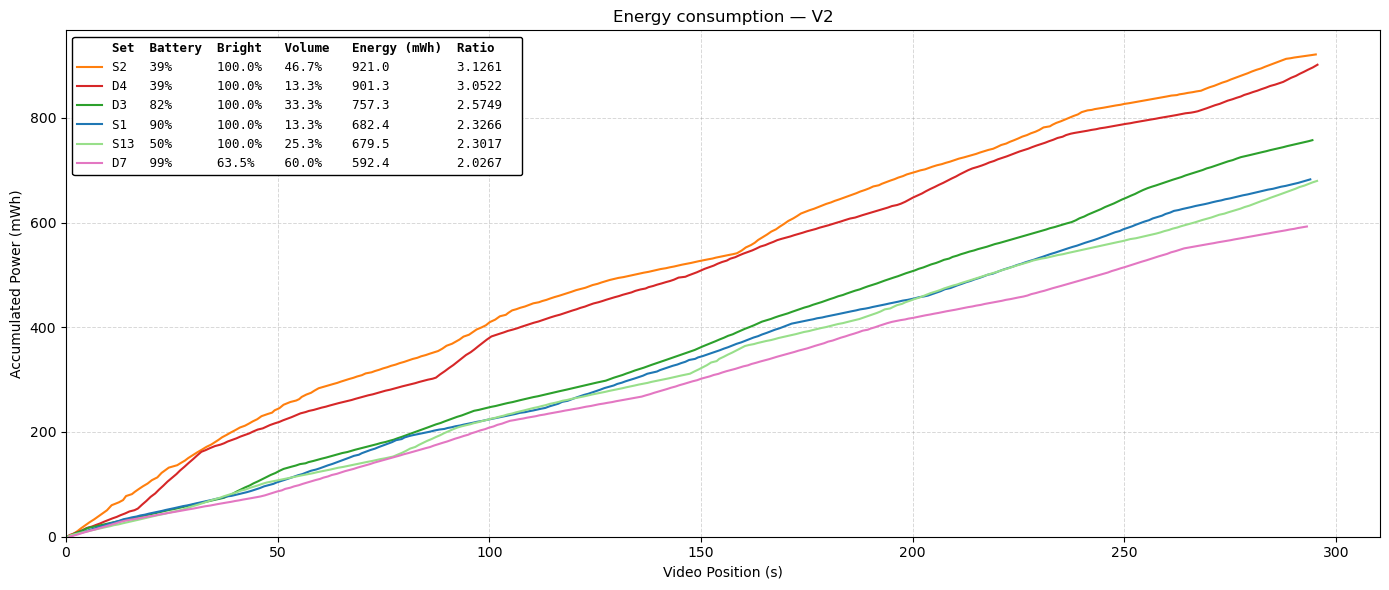

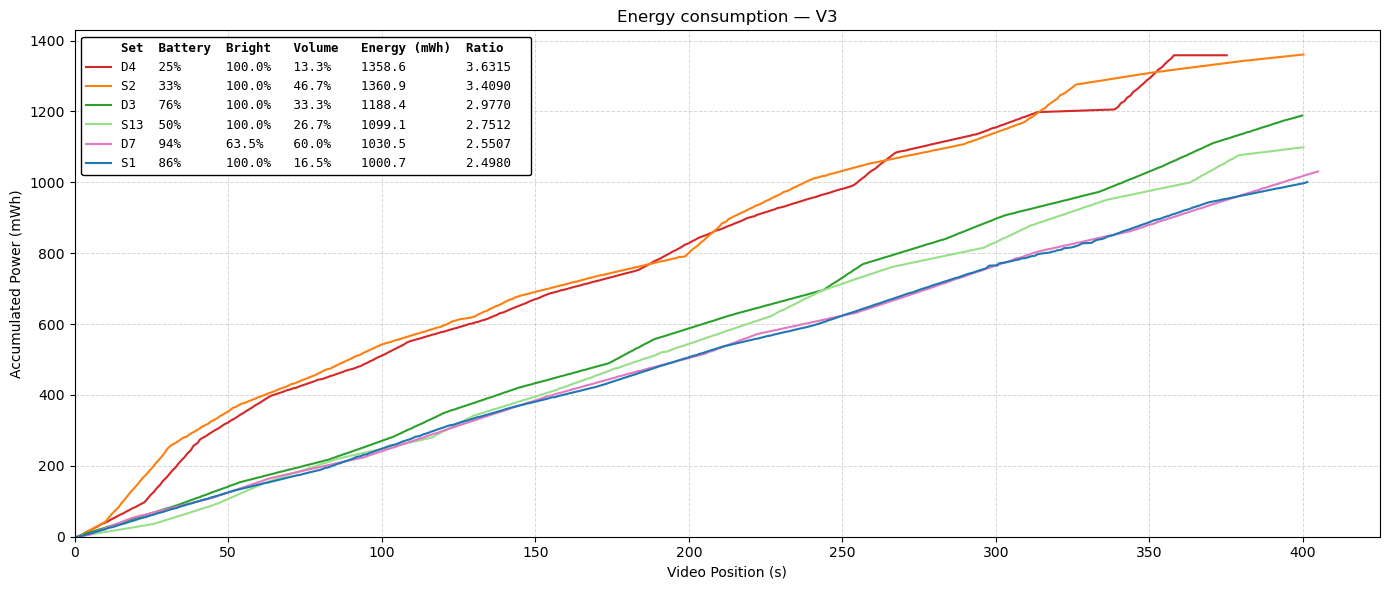

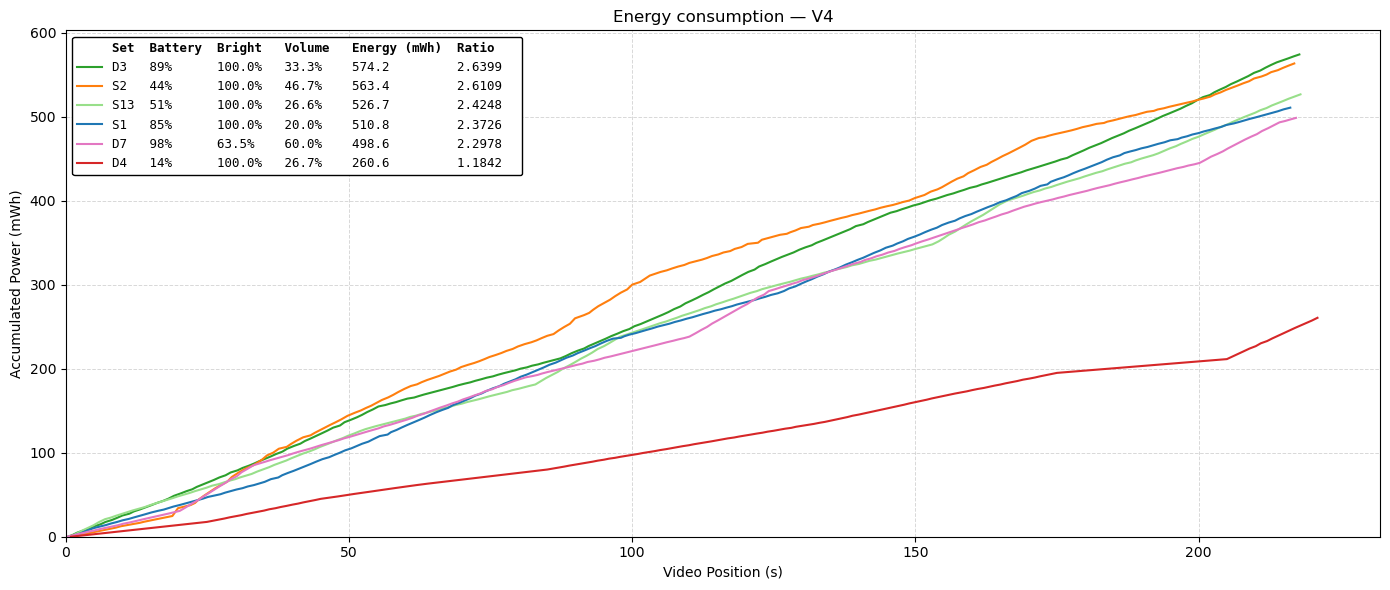

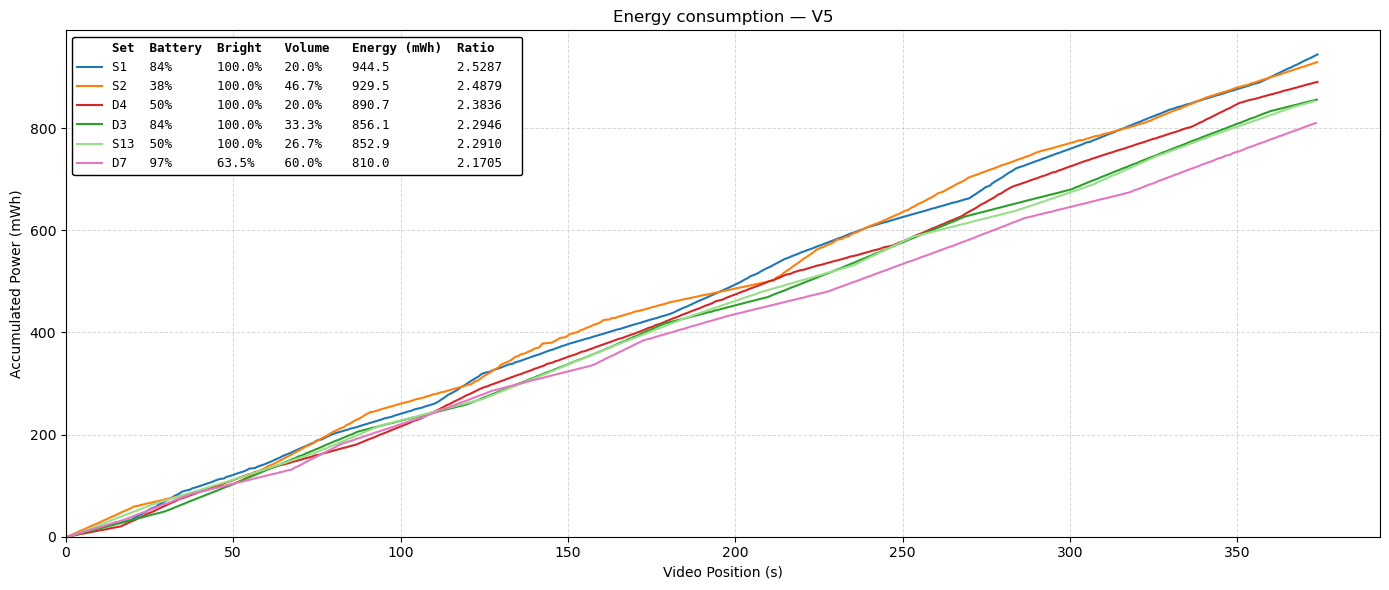

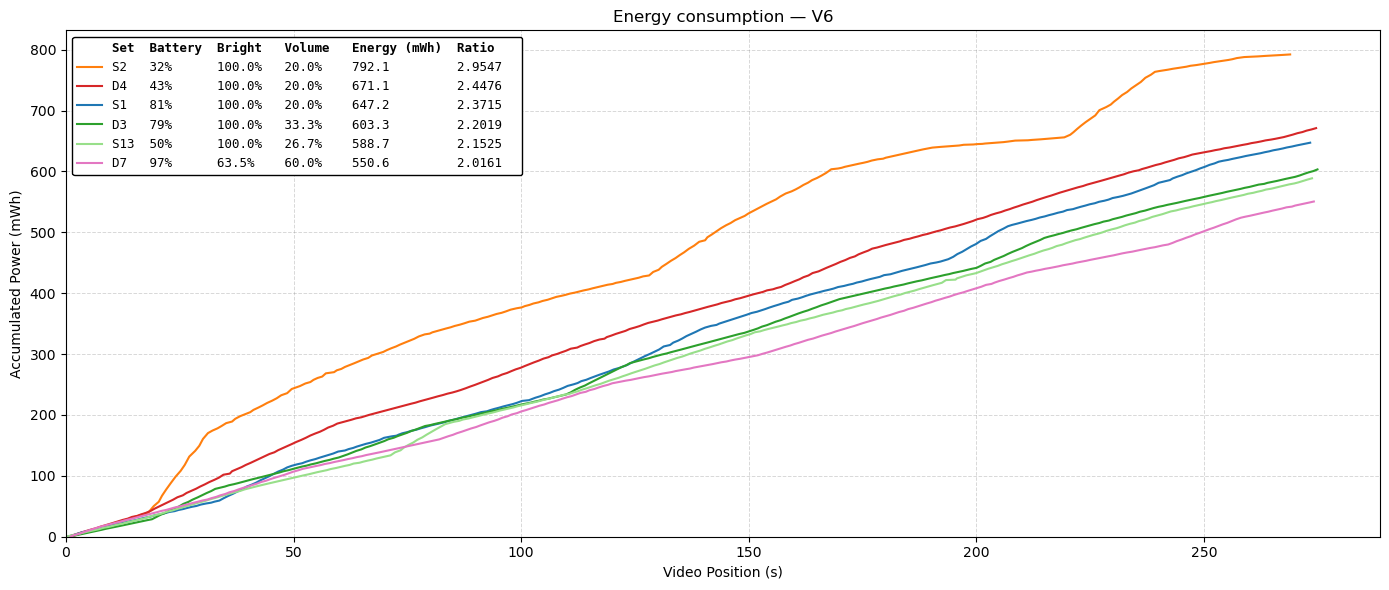

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.lines import Line2D

# Fixed color per set, the same in every graph
# (strong colors first, so S1–S10 are clearly distinct)
palette = plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]
all_sets = sorted(df_all["set_id"].unique(), key=lambda s: int(s[1:]))
SET_COLORS = {s: palette[i % len(palette)] for i, s in enumerate(all_sets)}

# Legend prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Legend column widths (characters); header and values share them, all left-aligned
COL_W = {"set": 5, "battery": 9, "bright": 9, "volume": 9, "energy": 14, "ratio": 8}


def legend_row(set_txt, battery, bright, volume, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{battery:<{COL_W['battery']}}"
            f"{bright:<{COL_W['bright']}}{volume:<{COL_W['volume']}}"
            f"{energy:<{COL_W['energy']}}{ratio:<{COL_W['ratio']}}")


def plot_video(vd):
    """Accumulated power over video position for one video, one line per set."""
    v = df_all[(df_all["vd_id"] == vd)
               & (df_all["user_state"] != "SQ")                   # Removing Sequences
               & (~df_all["set_id"].isin(["S10", "S11"]))].copy() # Removing specific Sets
    if v.empty:
        print(f"No data for {vd}")
        return

    # Shift each set's accumulated power so its first value is 0
    v["Accumulated Power from start (mWh)"] = (
        v["Accumulated Power (mWh)"]
        - v.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
    )

    # Per-set info for the legend
    info = v.groupby("set_id").agg(
        level_max=("Level (%)", "max"),
        user_state=("user_state", "first"),
        bright_avg=("Brightness (%)", "mean"),
        volume_avg=("Volume (%)", "mean"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )

    # Ratio: energy per second of video watched (zero length -> NaN)
    info["ratio"] = info["energy"] / info["video_length"].replace(0, np.nan)

    # Set order by ratio, highest first
    sets = info.sort_values("ratio", ascending=False).index.tolist()

    fig, ax = plt.subplots(figsize=(14, 6))

    for s in sets:
        d = v[v["set_id"] == s]
        r = info.loc[s]
        set_name = STATE_PREFIX.get(r.user_state, "?") + s[1:]   # e.g. S1 -> "S1" (ST), S3 -> "D3" (DY)
        label = legend_row(set_name,
                           f"{r.level_max:.0f}%",
                           f"{r.bright_avg:.1f}%",
                           f"{r.volume_avg:.1f}%",
                           f"{r.energy:.1f}",
                           f"{r.ratio:.4f}")
        ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
                label=label, color=SET_COLORS[s], linewidth=1.5)

    ax.set_xlabel("Video Position (s)")
    ax.set_ylabel("Accumulated Power (mWh)")
    ax.set_title(f"Energy consumption — {vd}")
    ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    # Legend inside the plot (upper left), in a box, with the header as the first row
    header = legend_row("Set", "Battery", "Bright", "Volume", "Energy (mWh)", "Ratio")
    handles, labels = ax.get_legend_handles_labels()
    header_handle = Line2D([], [], color="none")   # invisible line sample, keeps alignment

    leg = ax.legend([header_handle] + handles, [header] + labels,
                    loc="upper left", frameon=True,
                    facecolor="white", edgecolor="black", framealpha=1,
                    prop={"family": "monospace", "size": 9})
    leg.get_texts()[0].set_fontweight("bold")       # header row in bold

    fig.tight_layout()

    out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
    out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

    fig.savefig(out_dir / f"Energy_consumption_graph_{vd}.pdf", dpi=300, bbox_inches="tight")

    plt.show()


# One graph per video, V1 to V6
videos = sorted(df_all["vd_id"].unique(), key=lambda v: int(v[1:]))
for vd in videos:
    plot_video(vd)

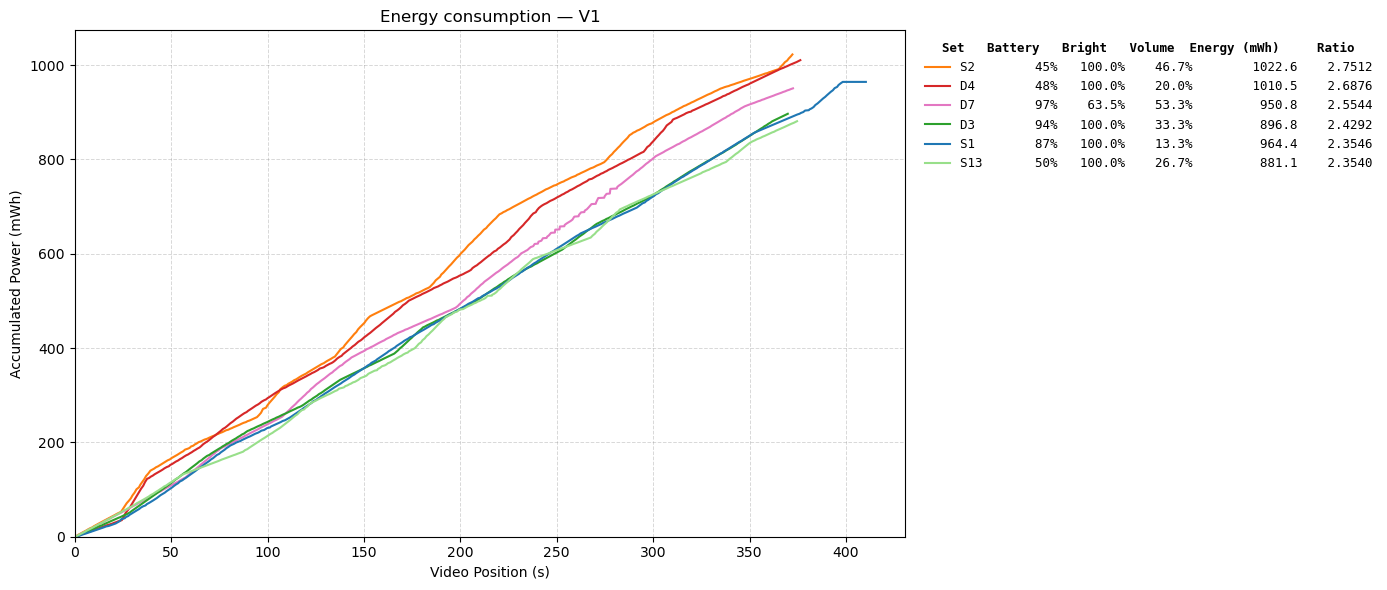

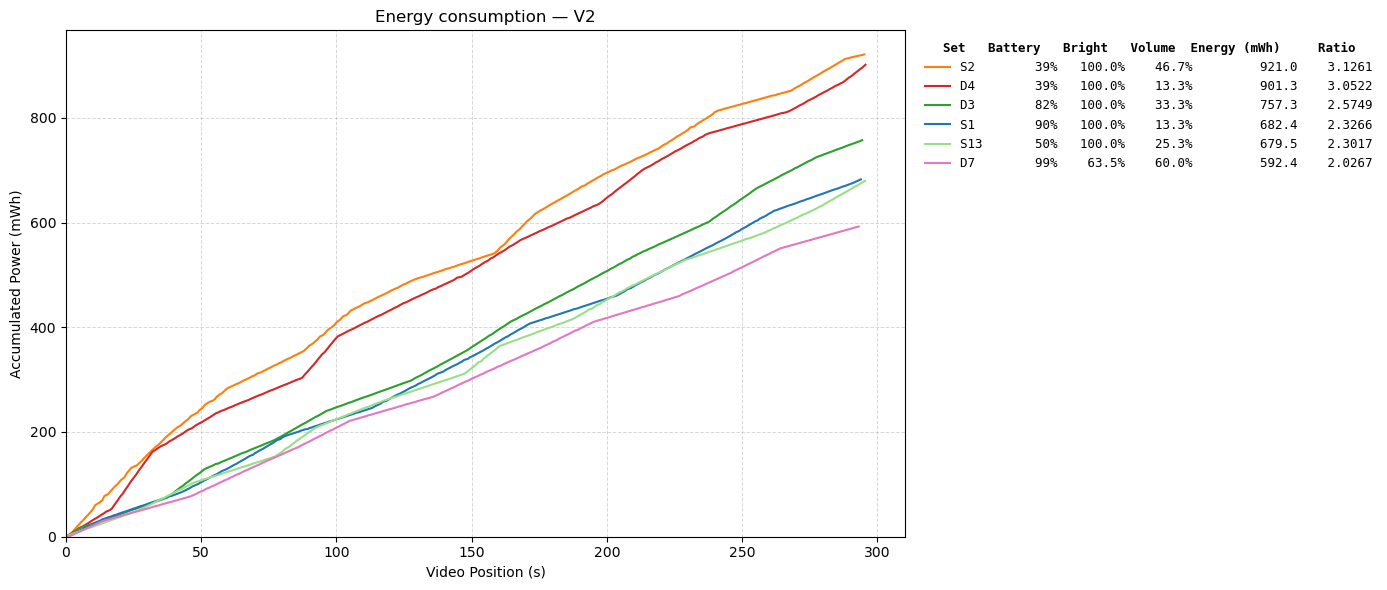

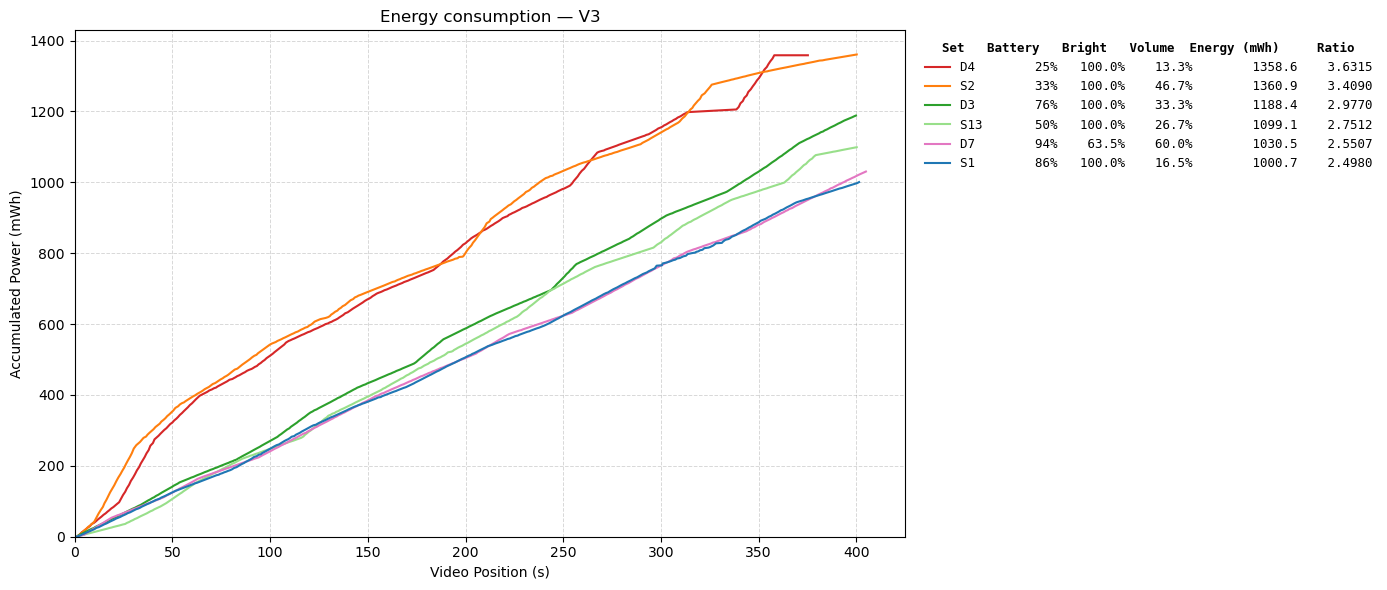

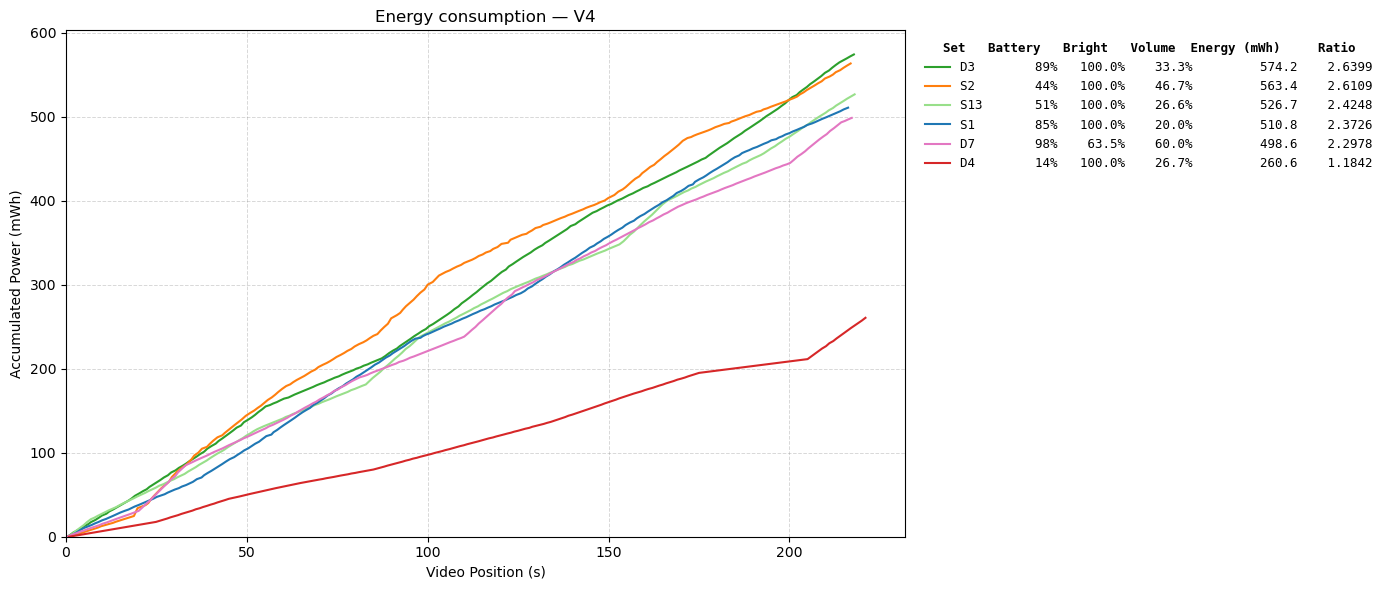

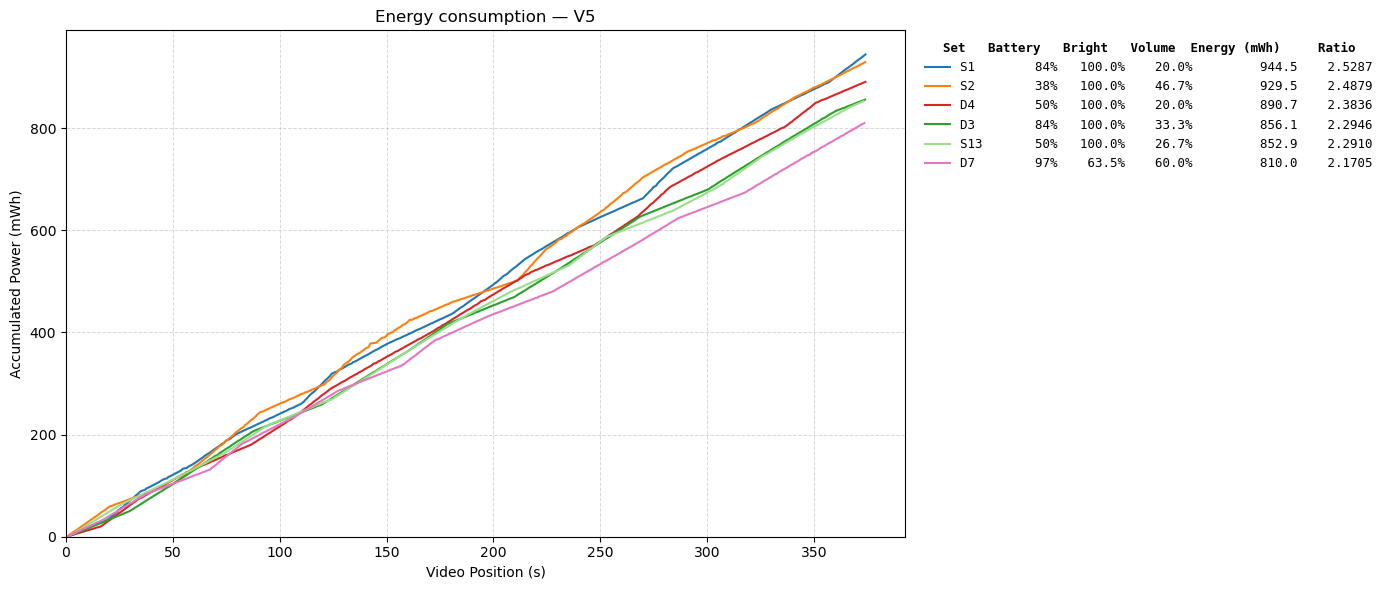

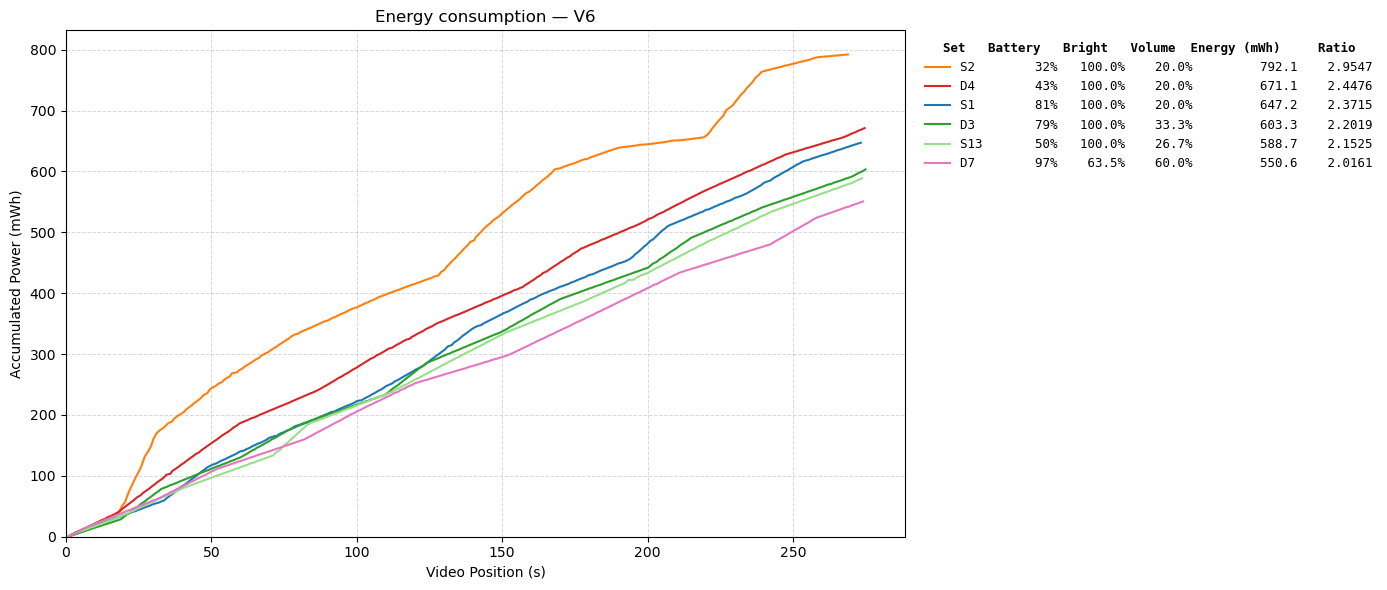

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Fixed color per set, the same in every graph
# (strong colors first, so S1–S10 are clearly distinct)
palette = plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]
all_sets = sorted(df_all["set_id"].unique(), key=lambda s: int(s[1:]))
SET_COLORS = {s: palette[i % len(palette)] for i, s in enumerate(all_sets)}

# Legend prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}


def plot_video(vd):
    """Accumulated power over video position for one video, one line per set."""
    v = df_all[(df_all["vd_id"] == vd)
               & (df_all["user_state"] != "SQ")                   # Removing Sequences
               & (~df_all["set_id"].isin(["S10", "S11"]))].copy() # Removing specific Sets
    if v.empty:
        print(f"No data for {vd}")
        return

    # Shift each set's accumulated power so its first value is 0
    v["Accumulated Power from start (mWh)"] = (
        v["Accumulated Power (mWh)"]
        - v.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
    )

    # Per-set info for the legend
    info = v.groupby("set_id").agg(
        level_max=("Level (%)", "max"),
        user_state=("user_state", "first"),
        bright_avg=("Brightness (%)", "mean"),
        volume_avg=("Volume (%)", "mean"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )

    # Ratio: energy per second of video watched (zero length -> NaN)
    info["ratio"] = info["energy"] / info["video_length"].replace(0, np.nan)

    # Set order by ratio, highest first
    sets = info.sort_values("ratio", ascending=False).index.tolist()

    fig, ax = plt.subplots(figsize=(14, 6))

    for s in sets:
        d = v[v["set_id"] == s]
        r = info.loc[s]
        set_name = STATE_PREFIX.get(r.user_state, "?") + s[1:]   # e.g. S1 -> "S1" (ST), S3 -> "D3" (DY)
        label = (f"{set_name:<4}  {r.level_max:>6.0f}%  "
                 f"{r.bright_avg:>6.1f}%  {r.volume_avg:>6.1f}%  "
                 f"{r.energy:>12.1f}  {r.ratio:>8.4f}")
        ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
                label=label, color=SET_COLORS[s], linewidth=1.5)

    ax.set_xlabel("Video Position (s)")
    ax.set_ylabel("Accumulated Power (mWh)")
    ax.set_title(f"Energy consumption — {vd}")
    ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    # Legend outside the plot, monospace so the columns align
    header = (f"{'Set':<4}  {'Battery':>7}  {'Bright':>7}  "
              f"{'Volume':>7}  {'Energy (mWh)':>12}  {'Ratio':>8}")
    ax.legend(title=header, bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False,
              prop={"family": "monospace", "size": 9},
              title_fontproperties={"family": "monospace", "size": 9, "weight": "bold"})

    fig.tight_layout()

    out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
    out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

    fig.savefig(out_dir / f"Energy_consumption_graph_{vd}.pdf", dpi=300, bbox_inches="tight")

    plt.show()


# One graph per video, V1 to V6
videos = sorted(df_all["vd_id"].unique(), key=lambda v: int(v[1:]))
for vd in videos:
    plot_video(vd)

NameError: name 'summary' is not defined

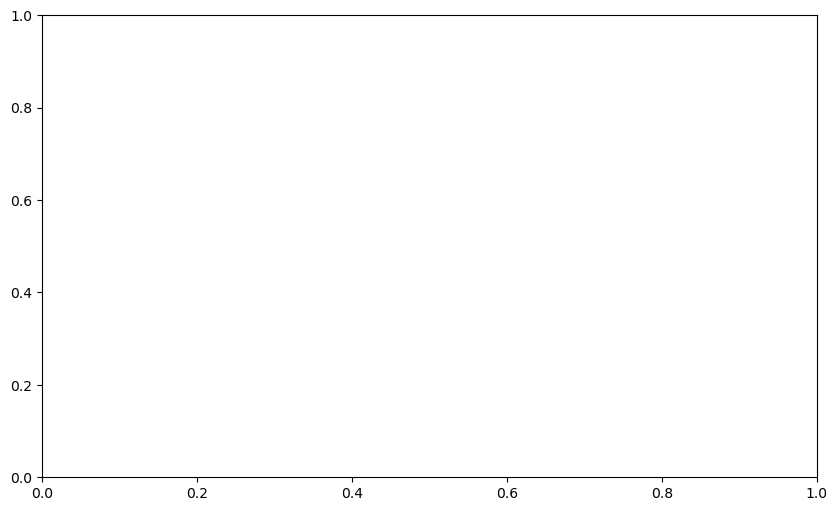

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

# Sets in numeric order (S1, S2, ..., S13) so the legend is sorted
set_order = sorted(summary["set_id"].unique(), key=lambda s: int(s[1:]))

for s in set_order:
    g = summary[summary["set_id"] == s]
    ax.scatter(g["level_max"], g["ratio"], color=SET_COLORS[s], marker="o",
               s=60, edgecolor="black", linewidth=0.5, label=g["set_name"].iloc[0])


ax.set_xlabel("Initial SOC (%)", labelpad=10)
ax.set_ylabel("Ratio consumption (mWh/s)", labelpad=10)
ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)

# Bold title, with the list of sets as a subtitle below it
set_list = sorted(summary["set_name"].unique(), key=lambda s: int(s[1:]))
title = fig.suptitle("Energy Consumption vs. SOC", fontsize=14, fontweight="bold")
ax.set_title(f"Sets {', '.join(set_list)}", fontsize=11, color="black", pad=10)

# X-axis from 0 to 100, numbered every 20, unnumbered ticks every 10
ax.set_xlim(0, 100)
ax.xaxis.set_major_locator(MultipleLocator(20))   # numbered ticks: 0, 20, 40, 60, 80, 100
ax.xaxis.set_minor_locator(MultipleLocator(10))   # unnumbered ticks: 10, 30, 50, 70, 90

# Y-axis: unnumbered ticks every 0.1
ax.yaxis.set_minor_locator(MultipleLocator(0.1))  # unnumbered ticks: 1.6, 1.7, ...

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)


# ax.legend(title="Set", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
# Legend in two rows: S sets on top, D sets below
handles, labels = ax.get_legend_handles_labels()
s_items = [(h, l) for h, l in zip(handles, labels) if l.startswith("S")]
d_items = [(h, l) for h, l in zip(handles, labels) if l.startswith("D")]

ncols = max(len(s_items), len(d_items))
blank = (Line2D([], [], linestyle="", marker=""), "")   # empty spacer
s_items += [blank] * (ncols - len(s_items))
d_items += [blank] * (ncols - len(d_items))

# Interleave so each column holds one S (top) and one D (bottom)
ordered = [item for pair in zip(s_items, d_items) for item in pair]
leg_handles, leg_labels = zip(*ordered)

ax.legend(leg_handles, leg_labels, title="Sets", ncol=ncols, loc="best",
          frameon=True, facecolor="white", edgecolor="black", framealpha=1,
          columnspacing=1.0, handletextpad=0.3)

fig.tight_layout()

# Center the main title over the plot area (same center as the subtitle)
pos = ax.get_position()
title.set_x(pos.x0 + pos.width / 2)

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "Ratio_vs_battery_scatter_by_set.pdf", dpi=300, bbox_inches="tight")

plt.show()

NameError: name 'summary' is not defined

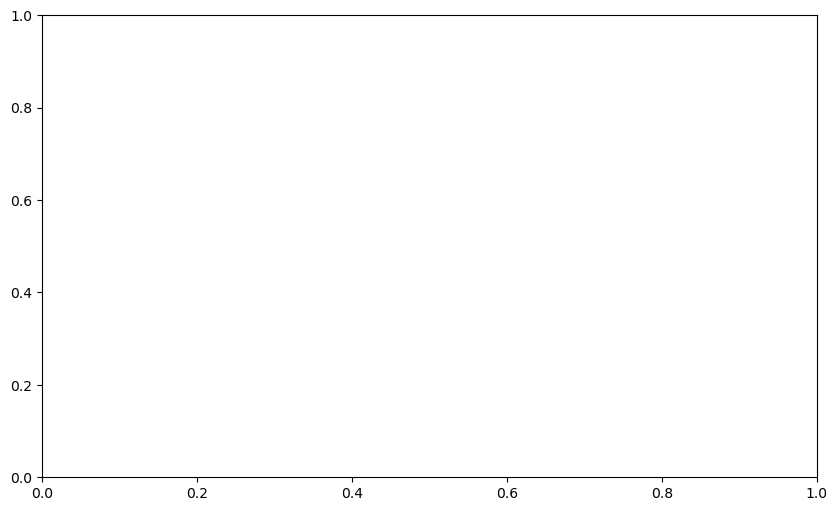

In [9]:
from matplotlib.ticker import MultipleLocator

# One color per group: S = ST sets, D = DY sets
GROUP_COLORS = {"S": "tab:blue", "D": "tab:red"}
GROUP_LABELS = {"S": "S (Static play)", "D": "D (Dynamic play)"}

fig, ax = plt.subplots(figsize=(10, 6))

for prefix, g in summary.groupby(summary["set_name"].str[0]):
    ax.scatter(g["level_max"], g["ratio"], color=GROUP_COLORS.get(prefix, "gray"),
               marker="o", s=60, edgecolor="black", linewidth=0.5,
               label=GROUP_LABELS.get(prefix, prefix), zorder=3, clip_on=False)

# Axis labels a bit further from their axes
ax.set_xlabel("Initial SOC (%)", labelpad=10)
ax.set_ylabel("Ratio consumption (mWh/s)", labelpad=10)

# Bold title, with the list of sets as a subtitle below it
set_list = sorted(summary["set_name"].unique(), key=lambda s: int(s[1:]))
title = fig.suptitle("Energy Consumption vs. SOC", fontsize=14, fontweight="bold")
ax.set_title(f"Sets {', '.join(set_list)}", fontsize=11, color="black", pad=10)

# X-axis from 0 to 100, numbered every 20, unnumbered ticks every 10
ax.set_xlim(0, 100)
ax.xaxis.set_major_locator(MultipleLocator(20))   # numbered ticks: 0, 20, 40, 60, 80, 100
ax.xaxis.set_minor_locator(MultipleLocator(10))   # unnumbered ticks: 10, 30, 50, 70, 90

# Y-axis: unnumbered ticks every 0.1
ax.yaxis.set_minor_locator(MultipleLocator(0.1))  # unnumbered ticks: 1.6, 1.7, ...

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend in a box, inside the plot, placed where it overlaps the fewest points
ax.legend(title="Group Sets", loc="best", frameon=True,
          facecolor="white", edgecolor="black", framealpha=1)

fig.tight_layout()

# Center the main title over the plot area (same center as the subtitle)
pos = ax.get_position()
title.set_x(pos.x0 + pos.width / 2)

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "Ratio_vs_battery_scatter_by_state.pdf", dpi=300, bbox_inches="tight")

plt.show()

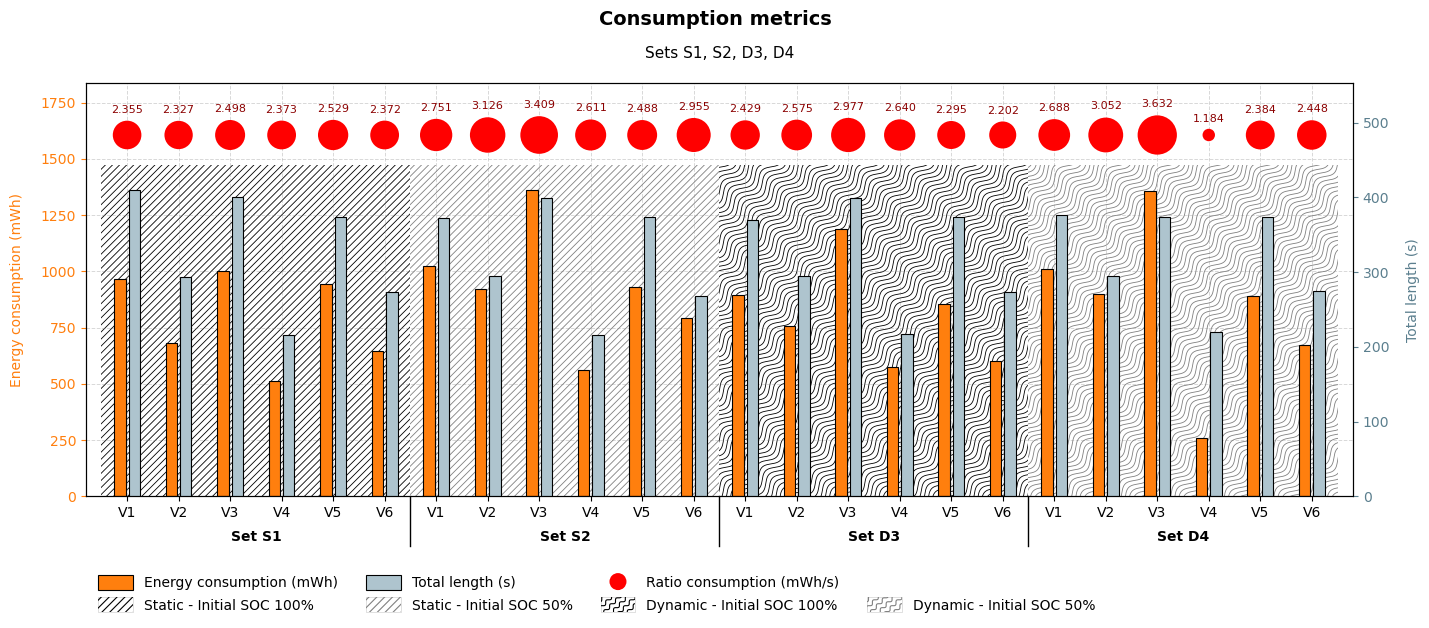

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerBase

# Sets to include on the x-axis (original IDs as they appear in the data)
SETS = ["S1", "S2", "S3", "S4"]

# Display prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Colors
CONS_COLOR = "tab:orange"        # energy consumption bars
LENGTH_COLOR = "#AEC4CE"         # total length bars (light blue-grey)
LENGTH_TEXT_COLOR = "#5B7F8E"    # darker blue-grey for the right axis text (readable)
BAR_EDGE = dict(edgecolor="black", linewidth=0.8)   # thin black outline on bars

# Background pattern per set (by display name): (line color, curved?)
BG_PATTERNS = {
    "S1": ("black", False),   # straight diagonal, black
    "S2": ("gray",  False),   # straight diagonal, gray
    "D3": ("black", True),    # curved diagonal, black
    "D4": ("gray",  True),    # curved diagonal, gray
}

# Legend text for each background style: (line color, curved?, label)
PATTERN_LEGEND = [
    ("black", False, "Static - Initial SOC 100%"),
    ("gray",  False, "Static - Initial SOC 50%"),
    ("black", True,  "Dynamic - Initial SOC 100%"),
    ("gray",  True,  "Dynamic - Initial SOC 50%"),
]


def diagonal_lines(x0, y0, x1, y1, curved, spacing, amplitude, wavelength, n=600):
    """Points for 45° diagonal lines (straight or wavy) covering the box (x0, y0)-(x1, y1)."""
    d = np.array([1, 1]) / np.sqrt(2)    # direction along the lines
    p = np.array([-1, 1]) / np.sqrt(2)   # direction between lines
    corners = np.array([[x0, y0], [x1, y0], [x0, y1], [x1, y1]])
    c_min, c_max = (corners @ p).min(), (corners @ p).max()
    t_min, t_max = (corners @ d).min(), (corners @ d).max()
    t = np.linspace(t_min, t_max, n)
    wave = amplitude * np.sin(2 * np.pi * t / wavelength) if curved else np.zeros_like(t)
    for c in np.arange(c_min, c_max + spacing, spacing):
        yield np.outer(t, d) + np.outer(c + wave, p)


def diagonal_background(ax, x0, x1, color, curved=False, y_top=1.0,
                        spacing=0.05, amplitude=0.04, wavelength=0.35, lw=0.6):
    """Diagonal lines behind the bars between x0 and x1, from the bottom of the plot
    up to y_top (fraction of the axes height). spacing, amplitude, wavelength in inches."""
    fig = ax.figure
    pos = ax.get_position()
    W = pos.width * fig.get_figwidth()     # axes width in inches
    H = pos.height * fig.get_figheight()   # axes height in inches
    xlo, xhi = ax.get_xlim()
    fx0, fx1 = (x0 - xlo) / (xhi - xlo), (x1 - xlo) / (xhi - xlo)

    clip = Rectangle((fx0, 0), fx1 - fx0, y_top, transform=ax.transAxes)
    for pts in diagonal_lines(fx0 * W, 0, fx1 * W, y_top * H, curved,
                              spacing, amplitude, wavelength):
        line, = ax.plot(pts[:, 0] / W, pts[:, 1] / H, transform=ax.transAxes,
                        color=color, linewidth=lw, zorder=0.2)
        line.set_clip_path(clip)


class DiagonalHandler(HandlerBase):
    """Legend swatch showing the diagonal pattern (straight or curved)."""
    def __init__(self, color, curved):
        super().__init__()
        self.color, self.curved = color, curved

    def create_artists(self, legend, orig_handle, xdescent, ydescent,
                       width, height, fontsize, trans):
        x0, y0 = -xdescent, -ydescent
        box = Rectangle((x0, y0), width, height, facecolor="white",
                        edgecolor="lightgray", linewidth=0.5, transform=trans)
        clip = Rectangle((x0, y0), width, height, transform=trans)
        artists = [box]
        for pts in diagonal_lines(x0, y0, x0 + width, y0 + height, self.curved,
                                  spacing=4, amplitude=1.0, wavelength=6, n=100):
            ln = Line2D(pts[:, 0], pts[:, 1], color=self.color, linewidth=0.8,
                        transform=trans)
            ln.set_clip_path(clip)
            artists.append(ln)
        return artists


subset = df_all[df_all["set_id"].isin(SETS) & (df_all["user_state"] != "SQ")]

# One row per (set, video): state, consumption, length and rate
bar_df = (
    subset.groupby(["set_id", "vd_id"])
    .agg(
        **{
            "user_state": ("user_state", "first"),
            "total_consumption (mWh)": ("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
            "total_length (s)": ("Video Position (s)", lambda p: p.max() - p.min()),
        }
    )
    .reset_index()
)
bar_df["consumption_rate (mWh/s)"] = (
    bar_df["total_consumption (mWh)"] / bar_df["total_length (s)"].replace(0, np.nan)
)

# Order: by set number, then video number
bar_df = bar_df.sort_values(
    ["set_id", "vd_id"], key=lambda c: c.str[1:].astype(int)
).reset_index(drop=True)

# Display names: S + number for Static sets, D + number for Dynamic sets
bar_df["set_name"] = bar_df["user_state"].map(STATE_PREFIX).fillna("?") + bar_df["set_id"].str[1:]

x = np.arange(len(bar_df))

width = 0.22   # thinner bars
gap = 0.06     # space between orange and blue-grey bars
offset = width / 2 + gap / 2

cons = bar_df["total_consumption (mWh)"]
length = bar_df["total_length (s)"]
ratio = bar_df["consumption_rate (mWh/s)"]

fig, ax1 = plt.subplots(figsize=(max(12, len(x) * 0.6), 6.5))   # wider for more bars
ax2 = ax1.twinx()   # second y-axis on the right

# Gray grid behind the bars
ax1.set_axisbelow(True)
ax1.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)

# Bars with a thin black outline
bars1 = ax1.bar(x - offset, cons, width, color=CONS_COLOR, **BAR_EDGE,
                label="Energy consumption (mWh)")
bars2 = ax2.bar(x + offset, length, width, color=LENGTH_COLOR, **BAR_EDGE,
                label="Total length (s)")

# Leave free space at the top of both axes for the circles
headroom = 1.35
ax1.set_ylim(0, cons.max() * headroom)
ax2.set_ylim(0, length.max() * headroom)

# Circle size scaled linearly with the ratio (smallest -> min_size, largest -> max_size)
min_size, max_size = 80, 800
r_min, r_max = ratio.min(), ratio.max()
if r_max > r_min:
    sizes = min_size + (ratio - r_min) / (r_max - r_min) * (max_size - min_size)
else:
    sizes = np.full(len(ratio), (min_size + max_size) / 2)

# Solid red circles, no outline
circle_y = cons.max() * 1.18
circles = ax1.scatter(x, np.full(len(x), circle_y), s=sizes, color="red",
                      edgecolors="none", zorder=3,
                      label="Ratio consumption (mWh/s)")

# Ratio value horizontal, centered, just above each circle (regular weight)
for xi, r, sz in zip(x, ratio, sizes):
    radius_pt = np.sqrt(sz / np.pi)   # circle radius in points
    ax1.annotate(f"{r:.3f}", (xi, circle_y), xytext=(0, radius_pt + 3),
                 textcoords="offset points", ha="center", va="bottom",
                 fontsize=8, fontweight="normal", color="darkred")

# Same small margin on both sides of the bars
side_margin = 0.8
ax1.set_xlim(-side_margin, len(x) - 1 + side_margin)

# Axes labels, colored to match their bars, a bit further from the axes
ax1.set_ylabel("Energy consumption (mWh)", color=CONS_COLOR, labelpad=12)
ax2.set_ylabel("Total length (s)", color=LENGTH_TEXT_COLOR, labelpad=12)
ax1.tick_params(axis="y", colors=CONS_COLOR)
ax2.tick_params(axis="y", colors=LENGTH_TEXT_COLOR)

# Tick labels V1..V6, with "Set S1", "Set S2", ... centered below each group
ax1.set_xticks(x)
ax1.set_xticklabels(bar_df["vd_id"])
groups = list(bar_df.groupby("set_name", sort=False))
for name, g in groups:
    ax1.text(g.index.to_numpy().mean(), -0.08, f"Set {name}",
             transform=ax1.get_xaxis_transform(), ha="center", va="top",
             fontsize=10, fontweight="bold")

# Short separator lines below the x-axis between sets
for _, g in groups[:-1]:
    sep_x = g.index.max() + 0.5
    ax1.plot([sep_x, sep_x], [0, -0.12], transform=ax1.get_xaxis_transform(),
             color="black", linewidth=1, clip_on=False)

# Legend: metrics on the first row, background patterns on the second
pattern_handles = [Patch(label=label) for _, _, label in PATTERN_LEGEND]
handler_map = {h: DiagonalHandler(color, curved)
               for h, (color, curved, _) in zip(pattern_handles, PATTERN_LEGEND)}
blank = Patch(visible=False, label="")

# Legend fills column by column, so interleave to get two clean rows
handles = [bars1, pattern_handles[0],
           bars2, pattern_handles[1],
           circles, pattern_handles[2],
           blank, pattern_handles[3]]
leg = ax1.legend(handles=handles, handler_map=handler_map,
                 loc="upper left", bbox_to_anchor=(0, -0.16), ncol=4,
                 frameon=False, handlelength=2.5, handleheight=1.3)
leg.legend_handles[handles.index(circles)].set_sizes([150])

# Subtitle with display names, e.g. "Sets S1, S2, D3, D4" (black, raised above the box)
display_sets = bar_df.drop_duplicates("set_id")["set_name"].tolist()
fig.suptitle("Consumption metrics", fontsize=14, fontweight="bold")
ax1.set_title(f"Sets {', '.join(display_sets)}", fontsize=11, color="black", pad=18)
fig.tight_layout()

# Where the patterns stop: just below the bottom of the largest circle
axes_h_in = ax1.get_position().height * fig.get_figheight()   # axes height in inches
circle_frac = circle_y / ax1.get_ylim()[1]                     # circle row, fraction of height
max_radius_in = np.sqrt(max_size / np.pi) / 72                 # largest circle radius, inches
pattern_gap_in = 0.08                                          # extra space below the circles
y_top = circle_frac - (max_radius_in + pattern_gap_in) / axes_h_in

# Background patterns per set (drawn after the layout is final)
for name, g in groups:
    if name in BG_PATTERNS:
        color, curved = BG_PATTERNS[name]
        diagonal_background(ax1, g.index.min() - 0.5, g.index.max() + 0.5,
                            color=color, curved=curved, y_top=y_top)

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed
fig.savefig(out_dir / "Consumption_metrics_selected_sets.pdf", dpi=300, bbox_inches="tight")

plt.show()